In [18]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import matplotlib as mpl
mpl.rcParams['legend.frameon'] = False
mpl.rcParams['font.size'] = 12
mpl.rcParams['font.sans-serif'] = 'Helvetica'
plt.rcParams['axes.unicode_minus'] = False


INPUT_CSV = Path("/home/digifort/Documents/Research_26/struc_comp/V_Bi/V_Bi_struc_comp.csv")
OUTPUT_FIGURE = Path("/home/digifort/Documents/Research_26/struc_comp/V_Bi/rdf_structures_16_28.png")
HIGHLIGHTED_STRUCTURES = [16, 28]

In [33]:
def main():
    df = pd.read_csv(INPUT_CSV)

    # RDF columns are stored as v_<distance>, e.g. v_2.50.
    rdf_columns = [col for col in df.columns if col.startswith("v_")]
    distances = [float(col.removeprefix("v_")) for col in rdf_columns]

    if "structures" not in df.columns:
        raise KeyError("The CSV must contain a 'structures' column.")

    missing = set(HIGHLIGHTED_STRUCTURES) - set(df["structures"])
    if missing:
        raise ValueError(f"These structures are absent from the CSV: {sorted(missing)}")

    fig, axes = plt.subplots(1, 2, figsize=(8, 4), sharey=True, constrained_layout=True)
    colors = {16: "tab:blue", 28: "tab:red"}

    # Exclude both highlighted RDFs from the grey background in both panels.
    background = df.loc[~df["structures"].isin(HIGHLIGHTED_STRUCTURES)]

    for ax, structure_id in zip(axes, HIGHLIGHTED_STRUCTURES):
        for _, row in background.iterrows():
            ax.plot(
                distances,
                row[rdf_columns],
                color="lightgrey",
                lw=0.7,
                alpha=0.40,
                zorder=1,
            )

        selected = df.loc[df["structures"] == structure_id].iloc[0]
        #label = f"Structure {structure_id}"
        if "Defect_Type" in df.columns:
            label = f" ({selected['Defect_Type']})" #label += f" ({selected['Defect_Type']})"

        ax.plot(
            distances,
            selected[rdf_columns],
            color=colors[structure_id],
            lw=1.8,
            ls="--",
            label=label,
            zorder=2,
        )
        ax.set_xlim(2,10.0)
        #ax.set_title(f"Structure {structure_id}")
        ax.set_xlabel(r"Distance ($\AA$)")
        ax.legend(frameon=False, loc="upper right")
        # Retain a full boxed frame, matching the PDP-plot styling.
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(1.0)
        

    axes[0].set_ylabel("RDF")
    axes[0].hlines(y=0, xmin=2, xmax=10, color="black", lw=1.0, ls="--", alpha=0.40, zorder=1)
    axes[1].hlines(y=0, xmin=2, xmax=10, color="black", lw=1.0, ls="--", alpha=0.40, zorder=1)
    
    fig.savefig(OUTPUT_FIGURE, dpi=600, bbox_inches="tight")
    plt.show()



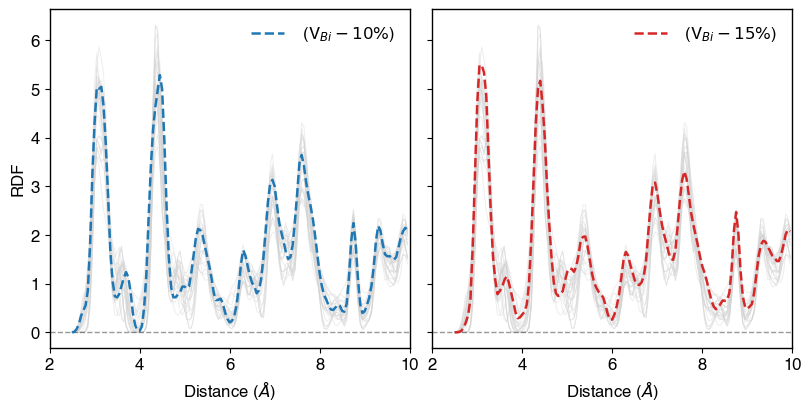

In [34]:
main()